In [1]:
# ============================================================
# STEP 1: INSTALL REQUIRED PACKAGES
# ============================================================

!pip install -U ultralytics kagglehub -q

print("Packages installed successfully.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.6/70.6 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 262.5/262.5 kB 19.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.9/63.9 kB 5.2 MB/s eta 0:00:00
Packages installed successfully.


In [2]:
# ============================================================
# STEP 2: IMPORT LIBRARIES
# ============================================================

import os
import random
import shutil
import yaml
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display, Video

import torch
import kagglehub

from ultralytics import YOLO

print("All libraries imported successfully.")

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
All libraries imported successfully.


In [3]:
# ============================================================
# STEP 3: GPU CHECK
# ============================================================

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):

    gpu_name = torch.cuda.get_device_name(i)

    gpu_memory = (
        torch.cuda.get_device_properties(i).total_memory
        / (1024 ** 3)
    )

    print(
        f"GPU {i}: {gpu_name} "
        f"({gpu_memory:.2f} GB)"
    )

PyTorch version: 2.10.0+cu128
CUDA available: True
GPU count: 2
GPU 0: Tesla T4 (14.56 GB)
GPU 1: Tesla T4 (14.56 GB)


In [4]:
# ============================================================
# STEP 4: DOWNLOAD DATASET
# ============================================================

dataset_path = kagglehub.dataset_download(
    "pkdarabi/cardetection"
)

print("Path to dataset files:")
print(dataset_path)

Path to dataset files:
/kaggle/input/datasets/pkdarabi/cardetection


In [5]:
# ============================================================
# STEP 5: INSPECT DATASET
# ============================================================

DATA_ROOT = Path(dataset_path)

print("Dataset root:")
print(DATA_ROOT)

print("\nDataset contents:\n")

for item in DATA_ROOT.iterdir():
    print(item)

Dataset root:
/kaggle/input/datasets/pkdarabi/cardetection

Dataset contents:

/kaggle/input/datasets/pkdarabi/cardetection/car
/kaggle/input/datasets/pkdarabi/cardetection/video.mp4


In [6]:
# ============================================================
# STEP 6: FIND DATA.YAML AUTOMATICALLY
# ============================================================

yaml_files = list(
    DATA_ROOT.rglob("data.yaml")
)

print(
    f"Found {len(yaml_files)} data.yaml file(s):\n"
)

for i, yaml_file in enumerate(yaml_files):

    print(
        f"[{i}] {yaml_file}"
    )

if not yaml_files:

    raise FileNotFoundError(
        "No data.yaml found inside the downloaded dataset."
    )

Found 1 data.yaml file(s):

[0] /kaggle/input/datasets/pkdarabi/cardetection/car/data.yaml


In [7]:
# ============================================================
# STEP 7: SET CORRECT DATASET PATHS
# ============================================================

DATA_ROOT = Path(dataset_path)

# Actual dataset directory
DATASET_DIR = DATA_ROOT / "car"

# Dataset YAML
DATA_YAML = DATASET_DIR / "data.yaml"

# Dataset splits
TRAIN_PATH = DATASET_DIR / "train" / "images"
VAL_PATH   = DATASET_DIR / "valid" / "images"
TEST_PATH  = DATASET_DIR / "test" / "images"

# Label directories
TRAIN_LABEL_PATH = DATASET_DIR / "train" / "labels"
VAL_LABEL_PATH   = DATASET_DIR / "valid" / "labels"
TEST_LABEL_PATH  = DATASET_DIR / "test" / "labels"


print("Dataset directory:")
print(DATASET_DIR)

print("\nData YAML:")
print(DATA_YAML)

print("\nTrain images:")
print(TRAIN_PATH)

print("\nValidation images:")
print(VAL_PATH)

print("\nTest images:")
print(TEST_PATH)

Dataset directory:
/kaggle/input/datasets/pkdarabi/cardetection/car

Data YAML:
/kaggle/input/datasets/pkdarabi/cardetection/car/data.yaml

Train images:
/kaggle/input/datasets/pkdarabi/cardetection/car/train/images

Validation images:
/kaggle/input/datasets/pkdarabi/cardetection/car/valid/images

Test images:
/kaggle/input/datasets/pkdarabi/cardetection/car/test/images


In [8]:
# ============================================================
# STEP 8: VERIFY DATASET PATHS
# ============================================================

paths_to_check = {
    "Dataset": DATASET_DIR,
    "data.yaml": DATA_YAML,

    "Train images": TRAIN_PATH,
    "Train labels": TRAIN_LABEL_PATH,

    "Validation images": VAL_PATH,
    "Validation labels": VAL_LABEL_PATH,

    "Test images": TEST_PATH,
    "Test labels": TEST_LABEL_PATH,
}


print("=" * 60)
print("DATASET PATH CHECK")
print("=" * 60)

all_paths_exist = True

for name, path in paths_to_check.items():

    exists = path.exists()

    print(
        f"{name:25} : {exists}"
    )

    if not exists:
        all_paths_exist = False


if not all_paths_exist:

    raise FileNotFoundError(
        "One or more dataset paths do not exist."
    )

print("\nAll dataset paths are valid.")

DATASET PATH CHECK
Dataset                   : True
data.yaml                 : True
Train images              : True
Train labels              : True
Validation images         : True
Validation labels         : True
Test images               : True
Test labels               : True

All dataset paths are valid.


In [9]:
# ============================================================
# STEP 9: READ DATA.YAML
# ============================================================

with open(DATA_YAML, "r") as f:

    data_config = yaml.safe_load(f)

print("Dataset configuration:")
print("=" * 60)

for key, value in data_config.items():

    print(
        f"{key}: {value}"
    )

Dataset configuration:
train: ../train/images
val: ../valid/images
test: ../test/images
nc: 15
names: ['Green Light', 'Red Light', 'Speed Limit 10', 'Speed Limit 100', 'Speed Limit 110', 'Speed Limit 120', 'Speed Limit 20', 'Speed Limit 30', 'Speed Limit 40', 'Speed Limit 50', 'Speed Limit 60', 'Speed Limit 70', 'Speed Limit 80', 'Speed Limit 90', 'Stop']
roboflow: {'workspace': 'selfdriving-car-qtywx', 'project': 'self-driving-cars-lfjou', 'version': 6, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/selfdriving-car-qtywx/self-driving-cars-lfjou/dataset/6'}


In [10]:
# ============================================================
# STEP 10: CLASS INFORMATION
# ============================================================

class_names = data_config.get(
    "names",
    []
)

num_classes = data_config.get(
    "nc",
    len(class_names)
)

print("Number of classes:")
print(num_classes)

print("\nClasses:")
print("-" * 40)

if isinstance(class_names, dict):

    for class_id, class_name in class_names.items():

        print(
            f"{class_id}: {class_name}"
        )

else:

    for class_id, class_name in enumerate(
        class_names
    ):

        print(
            f"{class_id}: {class_name}"
        )

Number of classes:
15

Classes:
----------------------------------------
0: Green Light
1: Red Light
2: Speed Limit 10
3: Speed Limit 100
4: Speed Limit 110
5: Speed Limit 120
6: Speed Limit 20
7: Speed Limit 30
8: Speed Limit 40
9: Speed Limit 50
10: Speed Limit 60
11: Speed Limit 70
12: Speed Limit 80
13: Speed Limit 90
14: Stop


In [11]:
# ============================================================
# STEP 11: FIND IMAGES AND LABELS
# ============================================================

IMAGE_EXTENSIONS = [
    "*.jpg",
    "*.jpeg",
    "*.png",
    "*.bmp",
    "*.webp"
]


def find_images(directory):

    images = []

    for extension in IMAGE_EXTENSIONS:

        images.extend(
            Path(directory).glob(extension)
        )

    return sorted(images)


train_images = find_images(
    TRAIN_PATH
)

val_images = find_images(
    VAL_PATH
)

test_images = find_images(
    TEST_PATH
)


train_labels = sorted(
    TRAIN_LABEL_PATH.glob("*.txt")
)

val_labels = sorted(
    VAL_LABEL_PATH.glob("*.txt")
)

test_labels = sorted(
    TEST_LABEL_PATH.glob("*.txt")
)


print("========== DATASET COUNTS ==========")

print(
    "Training images:",
    len(train_images)
)

print(
    "Training labels:",
    len(train_labels)
)

print(
    "Validation images:",
    len(val_images)
)

print(
    "Validation labels:",
    len(val_labels)
)

print(
    "Test images:",
    len(test_images)
)

print(
    "Test labels:",
    len(test_labels)
)

========== DATASET COUNTS ==========
Training images: 3530
Training labels: 3530
Validation images: 801
Validation labels: 801
Test images: 638
Test labels: 638


In [12]:
# ============================================================
# STEP 12: CHECK IMAGE / LABEL MATCHING
# ============================================================

def check_image_label_matching(
    images,
    labels
):

    image_stems = {
        image.stem
        for image in images
    }

    label_stems = {
        label.stem
        for label in labels
    }

    missing_labels = (
        image_stems - label_stems
    )

    missing_images = (
        label_stems - image_stems
    )

    return (
        missing_labels,
        missing_images
    )


train_missing_labels, train_missing_images = (
    check_image_label_matching(
        train_images,
        train_labels
    )
)

val_missing_labels, val_missing_images = (
    check_image_label_matching(
        val_images,
        val_labels
    )
)

test_missing_labels, test_missing_images = (
    check_image_label_matching(
        test_images,
        test_labels
    )
)


print("========== MATCHING CHECK ==========")

print(
    "Train images without labels:",
    len(train_missing_labels)
)

print(
    "Train labels without images:",
    len(train_missing_images)
)

print(
    "Validation images without labels:",
    len(val_missing_labels)
)

print(
    "Validation labels without images:",
    len(val_missing_images)
)

print(
    "Test images without labels:",
    len(test_missing_labels)
)

print(
    "Test labels without images:",
    len(test_missing_images)
)

========== MATCHING CHECK ==========
Train images without labels: 0
Train labels without images: 0
Validation images without labels: 0
Validation labels without images: 0
Test images without labels: 0
Test labels without images: 0


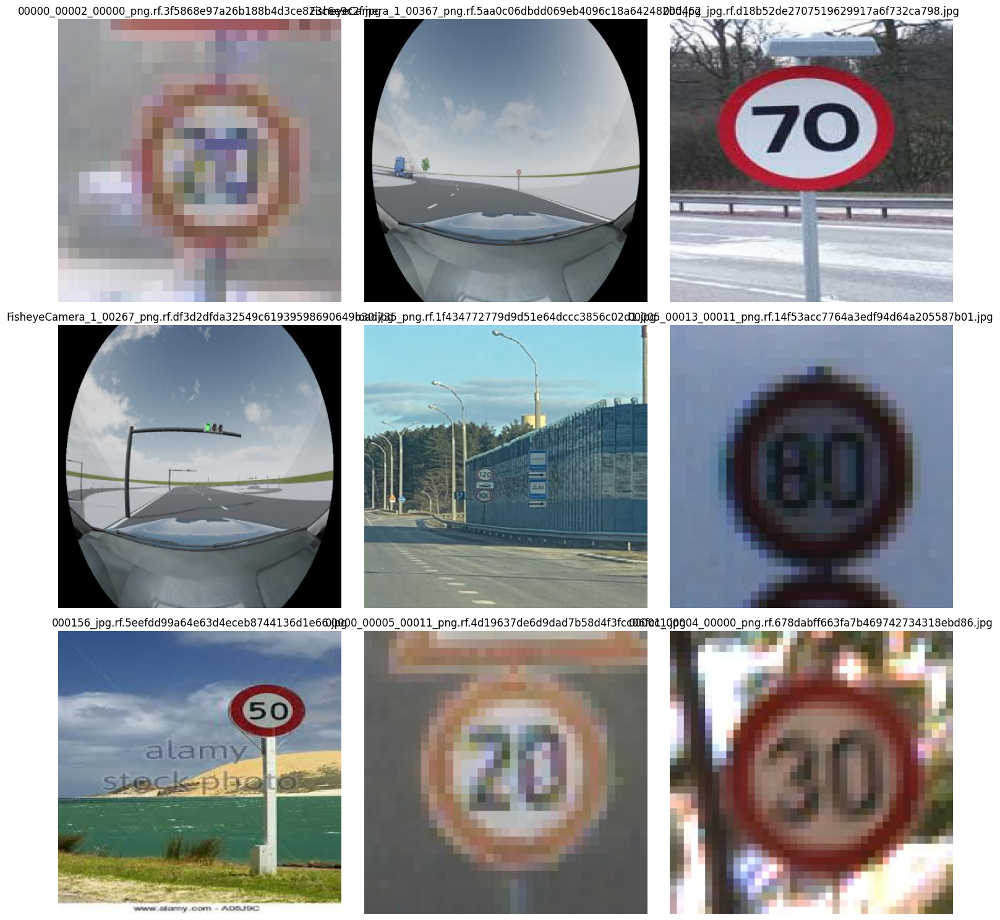

In [13]:
# ============================================================
# STEP 13: VISUALIZE TRAINING IMAGES
# ============================================================

NUM_SAMPLES = min(
    9,
    len(train_images)
)

selected_images = random.sample(
    train_images,
    NUM_SAMPLES
)

fig, axes = plt.subplots(
    3,
    3,
    figsize=(15, 15)
)

axes = axes.flatten()

for i, image_path in enumerate(
    selected_images
):

    image = cv2.imread(
        str(image_path)
    )

    if image is None:
        continue

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    axes[i].imshow(image)

    axes[i].set_title(
        image_path.name
    )

    axes[i].axis("off")


for i in range(
    NUM_SAMPLES,
    9
):

    axes[i].axis("off")


plt.tight_layout()
plt.show()

In [14]:
# ============================================================
# STEP 14: VISUALIZE YOLO LABELS
# ============================================================

def draw_yolo_labels(
    image_path,
    label_path,
    class_names
):

    image = cv2.imread(
        str(image_path)
    )

    if image is None:
        return None

    height, width = image.shape[:2]

    if label_path.exists():

        with open(
            label_path,
            "r"
        ) as f:

            lines = f.readlines()

        for line in lines:

            parts = line.strip().split()

            if len(parts) != 5:
                continue

            class_id = int(parts[0])

            x_center = float(parts[1])
            y_center = float(parts[2])

            box_width = float(parts[3])
            box_height = float(parts[4])

            x1 = int(
                (x_center - box_width / 2)
                * width
            )

            y1 = int(
                (y_center - box_height / 2)
                * height
            )

            x2 = int(
                (x_center + box_width / 2)
                * width
            )

            y2 = int(
                (y_center + box_height / 2)
                * height
            )

            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

            if isinstance(
                class_names,
                dict
            ):

                class_name = class_names.get(
                    class_id,
                    str(class_id)
                )

            else:

                class_name = (
                    class_names[class_id]
                    if class_id < len(class_names)
                    else str(class_id)
                )

            cv2.putText(
                image,
                class_name,
                (x1, max(y1 - 5, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (0, 255, 0),
                2
            )

    return cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

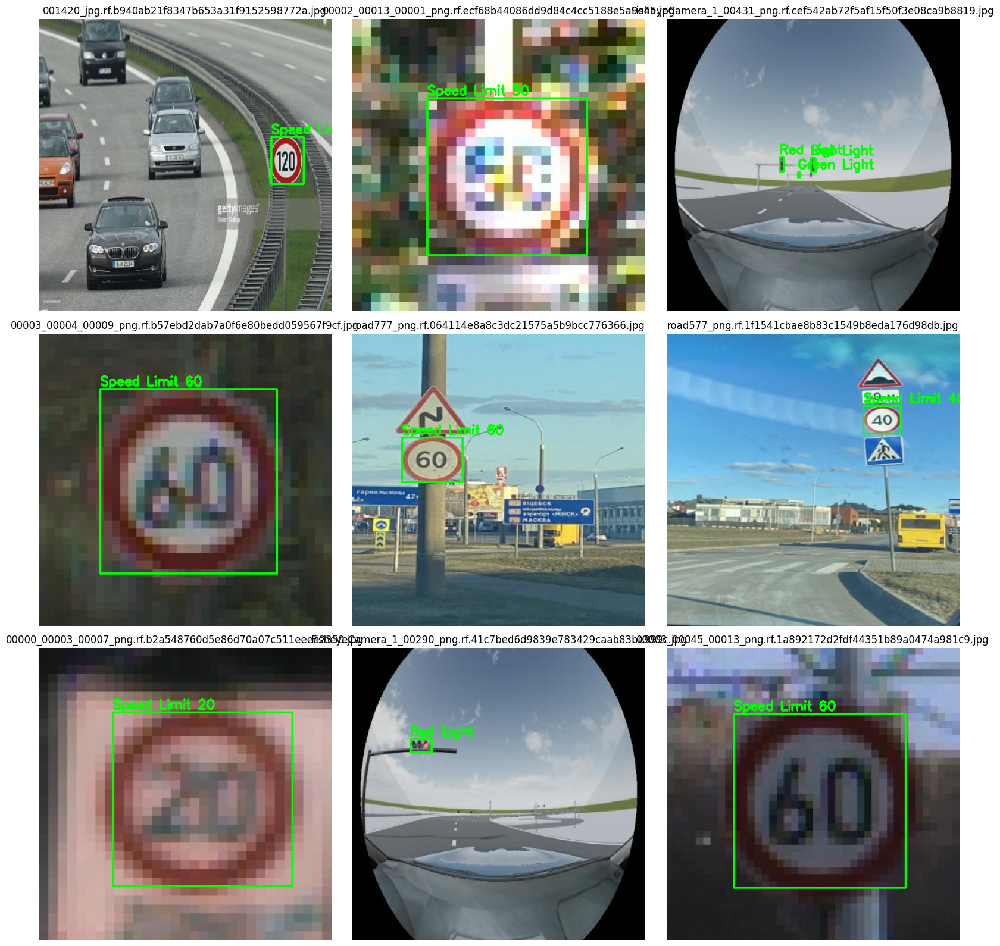

In [15]:
# ============================================================
# STEP 14B: SHOW GROUND TRUTH
# ============================================================

NUM_SAMPLES = min(
    9,
    len(train_images)
)

selected_images = random.sample(
    train_images,
    NUM_SAMPLES
)

fig, axes = plt.subplots(
    3,
    3,
    figsize=(16, 16)
)

axes = axes.flatten()

for i, image_path in enumerate(
    selected_images
):

    label_path = (
        TRAIN_LABEL_PATH /
        f"{image_path.stem}.txt"
    )

    annotated = draw_yolo_labels(
        image_path,
        label_path,
        class_names
    )

    axes[i].imshow(
        annotated
    )

    axes[i].set_title(
        image_path.name
    )

    axes[i].axis("off")


for i in range(
    NUM_SAMPLES,
    9
):

    axes[i].axis("off")


plt.tight_layout()
plt.show()

In [16]:
# ============================================================
# STEP 15: IMAGE DIMENSION ANALYSIS
# ============================================================

widths = []
heights = []

for image_path in train_images[:1000]:

    image = cv2.imread(
        str(image_path)
    )

    if image is None:
        continue

    height, width = image.shape[:2]

    widths.append(width)
    heights.append(height)


print(
    "Images analyzed:",
    len(widths)
)

if widths:

    print(
        "Average width:",
        round(np.mean(widths), 2)
    )

    print(
        "Average height:",
        round(np.mean(heights), 2)
    )

    print(
        "Minimum width:",
        np.min(widths)
    )

    print(
        "Maximum width:",
        np.max(widths)
    )

    print(
        "Minimum height:",
        np.min(heights)
    )

    print(
        "Maximum height:",
        np.max(heights)
    )

Images analyzed: 1000
Average width: 416.0
Average height: 416.0
Minimum width: 416
Maximum width: 416
Minimum height: 416
Maximum height: 416


In [17]:
# ============================================================
# STEP 16: YOLO26 CONFIGURATION
# ============================================================

MODEL_NAME = "yolo26n.pt"

IMG_SIZE = 640

EPOCHS = 100

# Automatically determine batch size
BATCH_SIZE = -1

WORKERS = 4

# ============================================================
# BOTH TESLA T4 GPUs
# ============================================================

DEVICE = [0, 1]

SEED = 42

PROJECT_DIR = Path(
    "/kaggle/working/runs"
)

RUN_NAME = (
    "cardetection_yolo26_2gpu"
)


print("Model:", MODEL_NAME)
print("Image size:", IMG_SIZE)
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Devices:", DEVICE)
print("Workers:", WORKERS)

Model: yolo26n.pt
Image size: 640
Epochs: 100
Batch size: -1
Devices: [0, 1]
Workers: 4


In [18]:
# ============================================================
# STEP 17: LOAD YOLO26
# ============================================================

model = YOLO(
    MODEL_NAME
)

print(
    "YOLO26 model loaded:",
    MODEL_NAME
)

YOLO26 model loaded: yolo26n.pt


In [19]:
# ============================================================
# STEP 18: MODEL INFORMATION
# ============================================================

model.info()

YOLO26n summary: 260 layers, 2,572,280 parameters, 0 gradients, 6.2 GFLOPs


(260, 2572280, 0, 6.2396672)

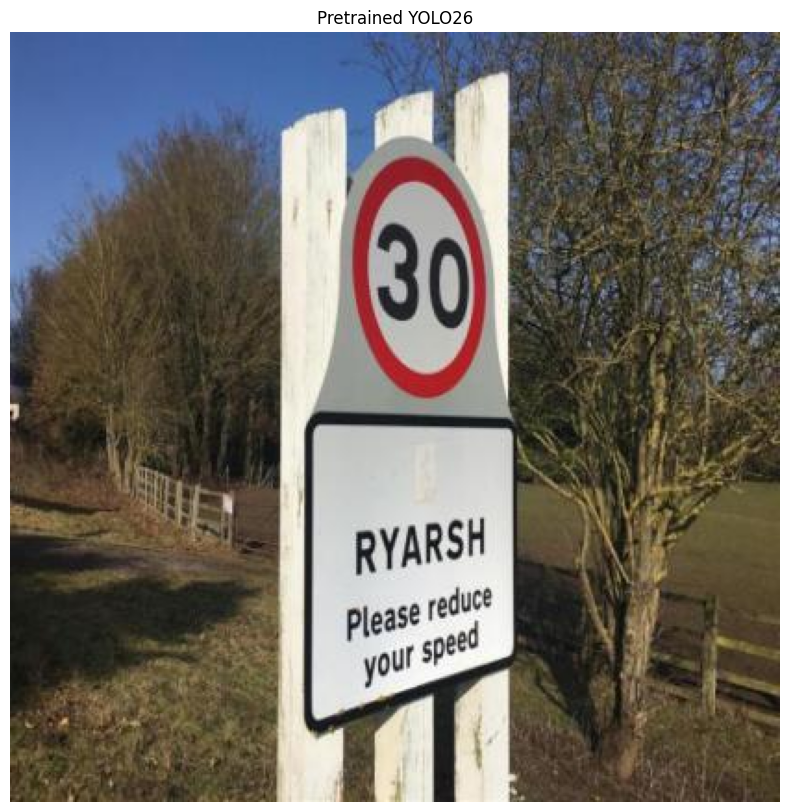

In [20]:
# ============================================================
# STEP 19: PRETRAINED YOLO26 TEST
# ============================================================

sample_image = train_images[0]

results = model.predict(

    source=str(sample_image),

    imgsz=IMG_SIZE,

    conf=0.25,

    device=0,

    verbose=False
)

annotated = results[0].plot()

plt.figure(
    figsize=(10, 10)
)

plt.imshow(
    cv2.cvtColor(
        annotated,
        cv2.COLOR_BGR2RGB
    )
)

plt.title(
    "Pretrained YOLO26"
)

plt.axis("off")

plt.show()

In [21]:
# ============================================================
# STEP 20: YOLO26 2-GPU TRAINING
# ============================================================

from ultralytics import YOLO
from pathlib import Path

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

MODEL_NAME = "yolo26n.pt"

IMG_SIZE = 640
EPOCHS = 100

# IMPORTANT:
# AutoBatch (-1) does NOT work with Multi-GPU.
# Batch must be an explicit positive multiple of GPU count.
BATCH_SIZE = 16

DEVICE = [0, 1]

WORKERS = 4

PROJECT_DIR = Path(
    "/kaggle/working/runs"
)

RUN_NAME = "cardetection_yolo26_2gpu"


# ------------------------------------------------------------
# Load pretrained YOLO26
# ------------------------------------------------------------

model = YOLO(
    MODEL_NAME
)


# ------------------------------------------------------------
# Train
# ------------------------------------------------------------

results = model.train(

    # Dataset
    data=str(DATA_YAML),

    # Image size
    imgsz=IMG_SIZE,

    # Training epochs
    epochs=EPOCHS,

    # Explicit batch for multi-GPU
    batch=BATCH_SIZE,

    # BOTH Tesla T4 GPUs
    device=DEVICE,

    # DataLoader
    workers=WORKERS,

    # Optimizer
    optimizer="auto",

    # Validation
    val=True,

    # Save checkpoints
    save=True,

    save_period=10,

    # Early stopping
    patience=20,

    # Reproducibility
    seed=42,

    # Output
    project=str(PROJECT_DIR),

    name=RUN_NAME,

    exist_ok=True,

    # Generate training plots
    plots=True,

    verbose=True
)

Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/pkdarabi/cardetection/car/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0

In [22]:
# ============================================================
# STEP 21: GPU MONITOR
# ============================================================

!nvidia-smi

Sun Aug 16 10:01:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.159.04             Driver Version: 580.159.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   72C    P0             33W /   70W |     243MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [23]:
# ============================================================
# STEP 22: CHECK TRAINING DIRECTORY
# ============================================================

from pathlib import Path

RUN_DIR = Path(
    "/kaggle/working/runs/cardetection_yolo26_2gpu"
)

print("Training directory:")
print(RUN_DIR)

print("\nContents:")

for item in RUN_DIR.iterdir():
    print(item.name)

Training directory:
/kaggle/working/runs/cardetection_yolo26_2gpu

Contents:
BoxPR_curve.png
val_batch1_labels.jpg
val_batch0_labels.jpg
train_batch19890.jpg
labels.jpg
results.png
val_batch1_pred.jpg
train_batch1.jpg
confusion_matrix.png
train_batch0.jpg
weights
args.yaml
confusion_matrix_normalized.png
train_batch19891.jpg
val_batch0_pred.jpg
BoxP_curve.png
BoxR_curve.png
results.csv
train_batch2.jpg
val_batch2_pred.jpg
train_batch19892.jpg
val_batch2_labels.jpg
BoxF1_curve.png


In [24]:
# ============================================================
# STEP 23: LOCATE BEST MODEL
# ============================================================

BEST_MODEL = (
    RUN_DIR /
    "weights" /
    "best.pt"
)

LAST_MODEL = (
    RUN_DIR /
    "weights" /
    "last.pt"
)

print("Best model:")
print(BEST_MODEL)

print("\nLast model:")
print(LAST_MODEL)

print("\nBest model exists:", BEST_MODEL.exists())
print("Last model exists:", LAST_MODEL.exists())

assert BEST_MODEL.exists(), (
    "best.pt was not found!"
)

print("\n✓ best.pt found successfully.")

Best model:
/kaggle/working/runs/cardetection_yolo26_2gpu/weights/best.pt

Last model:
/kaggle/working/runs/cardetection_yolo26_2gpu/weights/last.pt

Best model exists: True
Last model exists: True

✓ best.pt found successfully.


In [25]:
# ============================================================
# STEP 24: LOAD BEST MODEL
# ============================================================

from ultralytics import YOLO

best_model = YOLO(
    str(BEST_MODEL)
)

print("✓ Best YOLO26 model loaded.")

✓ Best YOLO26 model loaded.


In [26]:
# ============================================================
# STEP 25: READ RESULTS CSV
# ============================================================

import pandas as pd

RESULTS_CSV = (
    RUN_DIR /
    "results.csv"
)

assert RESULTS_CSV.exists(), (
    "results.csv not found!"
)

results_df = pd.read_csv(
    RESULTS_CSV
)

results_df.columns = (
    results_df.columns.str.strip()
)

print(
    results_df.tail()
)

print("\nColumns:")
print(
    results_df.columns.tolist()
)

    epoch     time  train/box_loss  train/cls_loss  train/l1_loss  \
95     96  4652.67         0.62742         0.32194        0.00632   
96     97  4699.76         0.63322         0.33295        0.00603   
97     98  4746.72         0.64047         0.31395        0.00631   
98     99  4793.91         0.63712         0.33022        0.00621   
99    100  4840.78         0.65030         0.33266        0.00618   

    metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  \
95               0.94376            0.90208           0.95770   
96               0.92559            0.91734           0.95833   
97               0.93516            0.91153           0.95945   
98               0.94365            0.91080           0.96041   
99               0.94541            0.90176           0.95839   

    metrics/mAP50-95(B)  val/box_loss  val/cls_loss  val/l1_loss    lr/pg0  \
95              0.82144       0.62126       0.33567      0.00822  0.000031   
96              0.82213       0.62068 

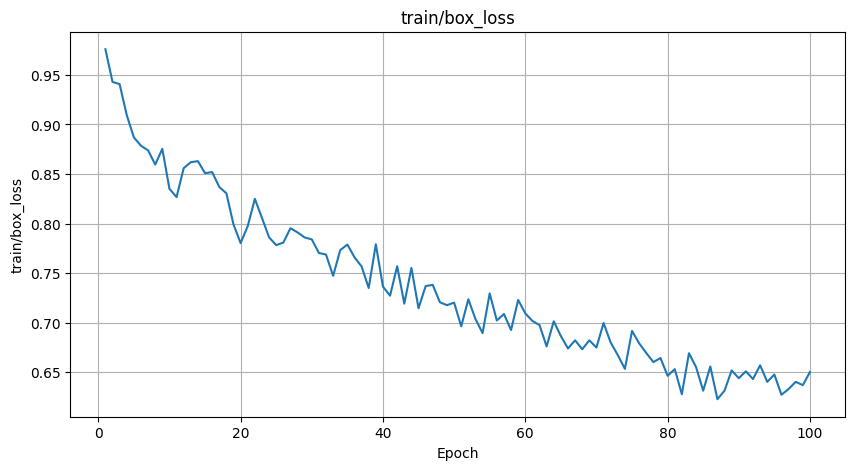

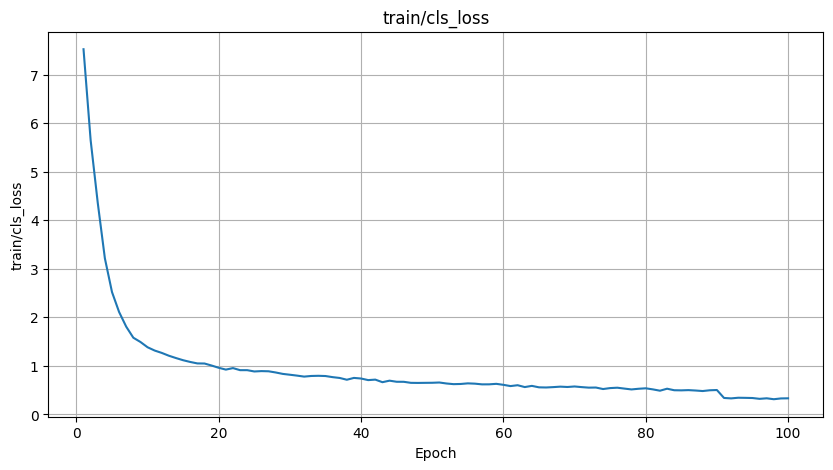

Skipping: train/dfl_loss


In [27]:
# ============================================================
# STEP 26: TRAINING LOSS
# ============================================================

import matplotlib.pyplot as plt

loss_columns = [
    "train/box_loss",
    "train/cls_loss",
    "train/dfl_loss"
]

for column in loss_columns:

    if column not in results_df.columns:
        print(f"Skipping: {column}")
        continue

    plt.figure(
        figsize=(10, 5)
    )

    plt.plot(
        results_df["epoch"],
        results_df[column]
    )

    plt.xlabel("Epoch")
    plt.ylabel(column)
    plt.title(column)

    plt.grid(True)
    plt.show()

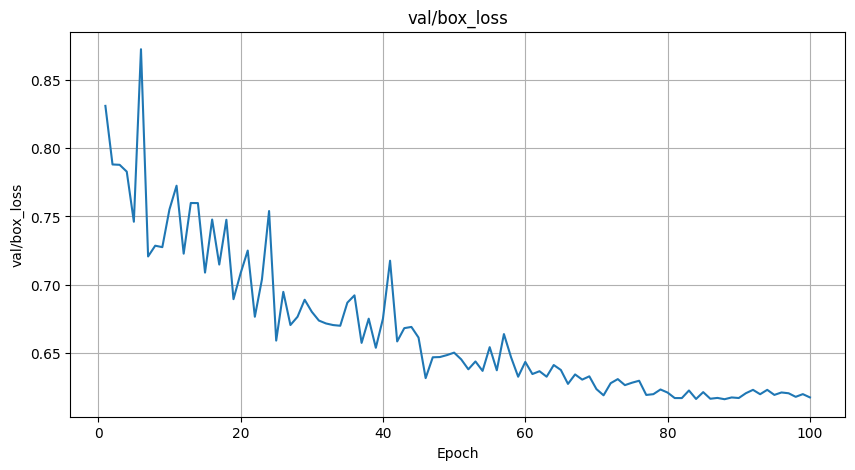

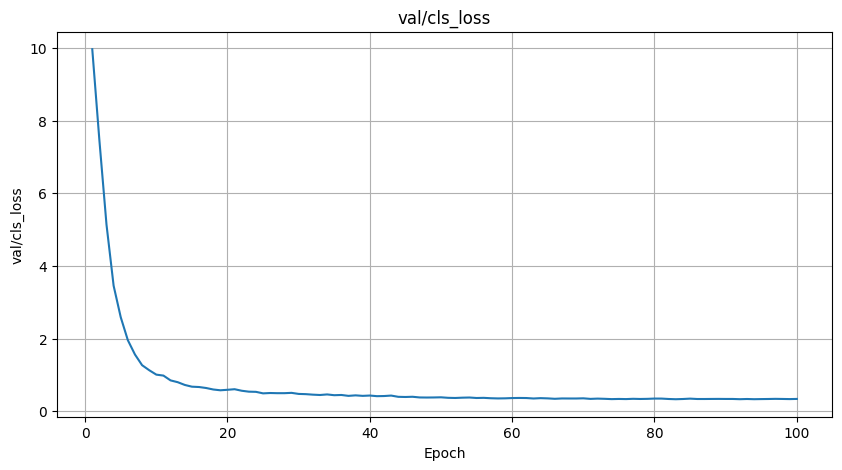

Skipping: val/dfl_loss


In [28]:
# ============================================================
# STEP 27: VALIDATION LOSS
# ============================================================

val_columns = [
    "val/box_loss",
    "val/cls_loss",
    "val/dfl_loss"
]

for column in val_columns:

    if column not in results_df.columns:
        print(f"Skipping: {column}")
        continue

    plt.figure(
        figsize=(10, 5)
    )

    plt.plot(
        results_df["epoch"],
        results_df[column]
    )

    plt.xlabel("Epoch")
    plt.ylabel(column)
    plt.title(column)

    plt.grid(True)
    plt.show()

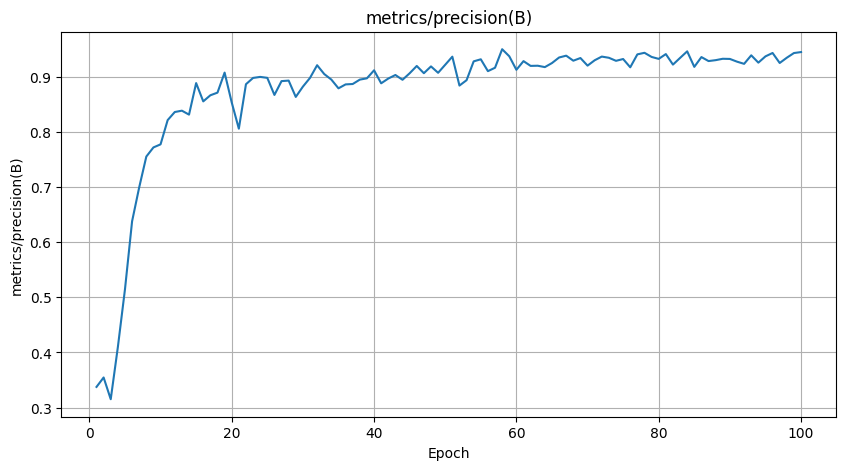

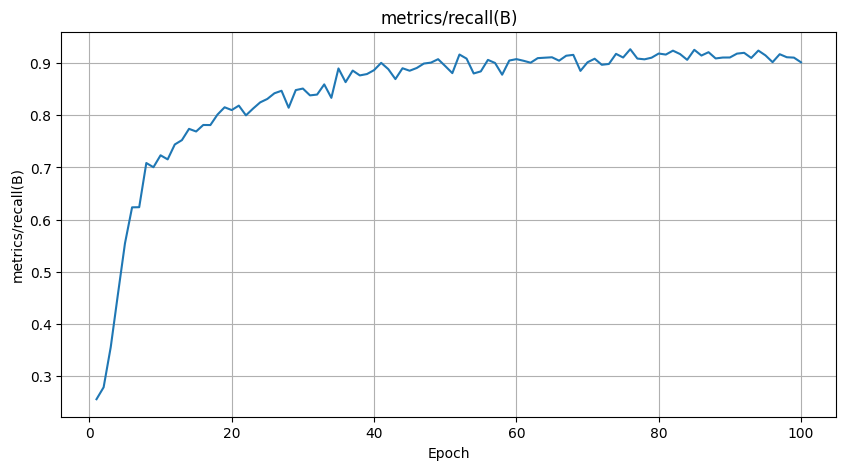

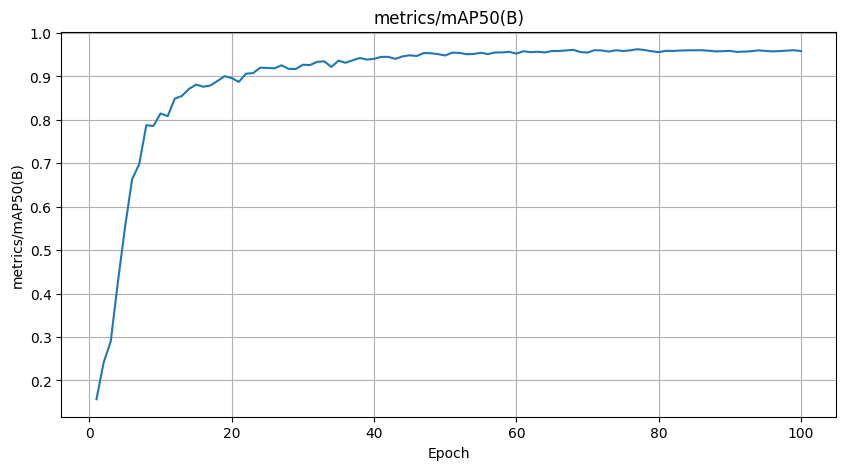

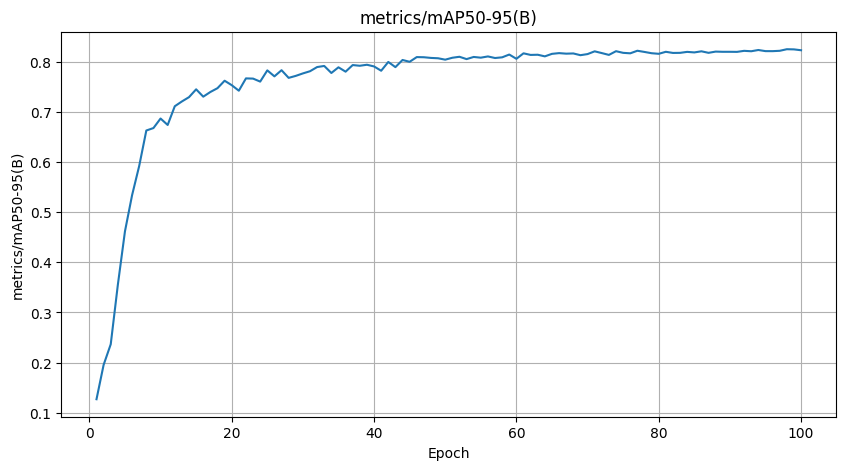

In [29]:
# ============================================================
# STEP 28: PRECISION / RECALL / MAP
# ============================================================

metric_columns = [
    "metrics/precision(B)",
    "metrics/recall(B)",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)"
]

for column in metric_columns:

    if column not in results_df.columns:
        print(f"Skipping: {column}")
        continue

    plt.figure(
        figsize=(10, 5)
    )

    plt.plot(
        results_df["epoch"],
        results_df[column]
    )

    plt.xlabel("Epoch")
    plt.ylabel(column)
    plt.title(column)

    plt.grid(True)
    plt.show()

In [30]:
# ============================================================
# STEP 29: BEST EPOCH
# ============================================================

MAP_COLUMN = "metrics/mAP50-95(B)"

if MAP_COLUMN in results_df.columns:

    best_index = (
        results_df[MAP_COLUMN].idxmax()
    )

    best_row = (
        results_df.loc[best_index]
    )

    print("========== BEST EPOCH ==========")

    print(
        "Epoch:",
        int(best_row["epoch"])
    )

    print(
        "mAP50-95:",
        round(
            best_row[MAP_COLUMN],
            4
        )
    )

    if "metrics/mAP50(B)" in results_df.columns:

        print(
            "mAP50:",
            round(
                best_row[
                    "metrics/mAP50(B)"
                ],
                4
            )
        )

    if "metrics/precision(B)" in results_df.columns:

        print(
            "Precision:",
            round(
                best_row[
                    "metrics/precision(B)"
                ],
                4
            )
        )

    if "metrics/recall(B)" in results_df.columns:

        print(
            "Recall:",
            round(
                best_row[
                    "metrics/recall(B)"
                ],
                4
            )
        )

========== BEST EPOCH ==========
Epoch: 98
mAP50-95: 0.8253
mAP50: 0.9594
Precision: 0.9352
Recall: 0.9115


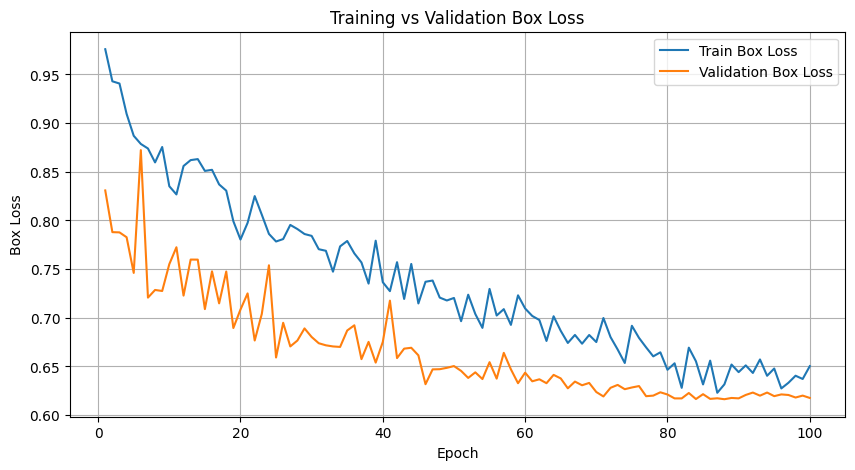

In [31]:
# ============================================================
# STEP 30: OVERFITTING ANALYSIS
# ============================================================

if (
    "train/box_loss" in results_df.columns
    and
    "val/box_loss" in results_df.columns
):

    plt.figure(
        figsize=(10, 5)
    )

    plt.plot(
        results_df["epoch"],
        results_df["train/box_loss"],
        label="Train Box Loss"
    )

    plt.plot(
        results_df["epoch"],
        results_df["val/box_loss"],
        label="Validation Box Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Box Loss")

    plt.title(
        "Training vs Validation Box Loss"
    )

    plt.legend()
    plt.grid(True)

    plt.show()

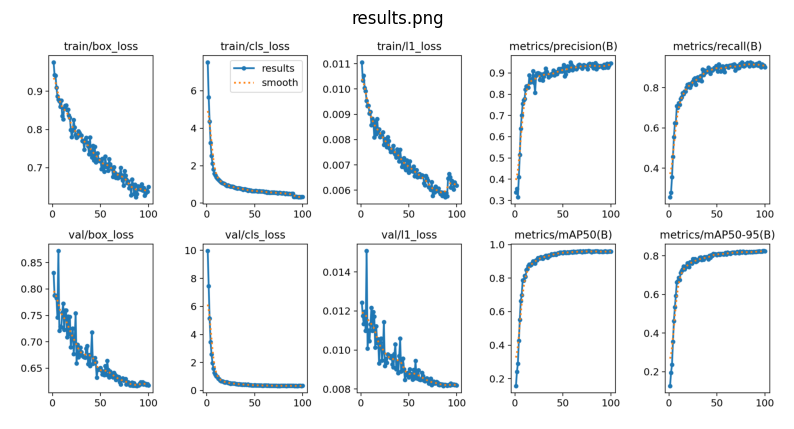

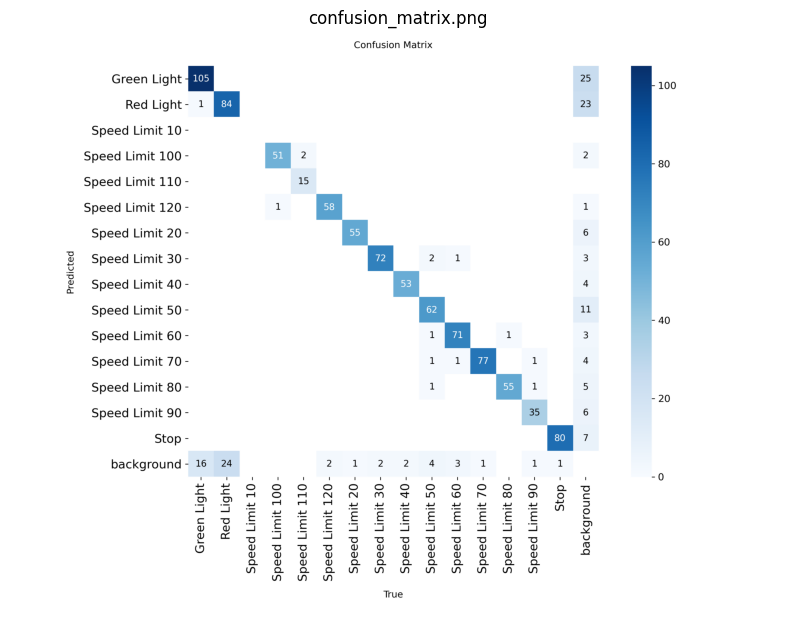

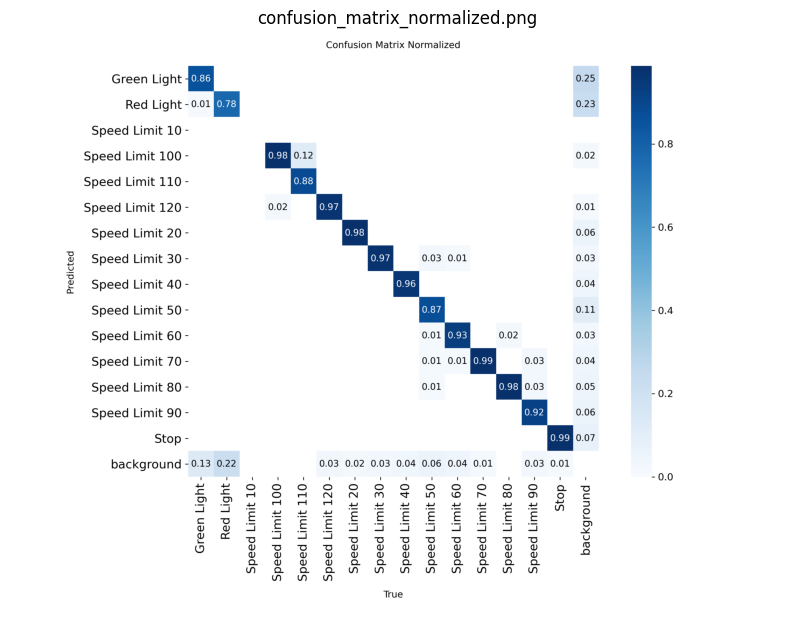

Not found: PR_curve.png
Not found: P_curve.png
Not found: R_curve.png
Not found: F1_curve.png


In [32]:
# ============================================================
# STEP 31: DISPLAY TRAINING PLOTS
# ============================================================

import cv2

plot_names = [
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "PR_curve.png",
    "P_curve.png",
    "R_curve.png",
    "F1_curve.png"
]

for plot_name in plot_names:

    plot_path = (
        RUN_DIR /
        plot_name
    )

    if not plot_path.exists():
        print(
            f"Not found: {plot_name}"
        )
        continue

    image = cv2.imread(
        str(plot_path)
    )

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(
        figsize=(10, 8)
    )

    plt.imshow(image)

    plt.title(
        plot_name
    )

    plt.axis("off")

    plt.show()

In [33]:
# ============================================================
# STEP 32: VALIDATION
# ============================================================

val_metrics = best_model.val(

    data=str(DATA_YAML),

    split="val",

    imgsz=640,

    device=0,

    plots=True
)

print(
    "✓ Validation completed."
)

Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 122 layers, 2,377,761 parameters, 0 gradients, 5.3 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 7.1±3.4 MB/s, size: 17.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning /kaggle/input/datasets/pkdarabi/cardetection/car/valid/labels... 801 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 801/801 298.5it/s 2.7s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/pkdarabi/cardetection/car/valid is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 51/51 7.1it/s 7.2s
                   all        801        944      0.938      0.908      0.958      0.825
           Green Light         87        122      0.878      0.767      0.872      0.516
             R

In [34]:
# ============================================================
# STEP 33: VALIDATION METRICS
# ============================================================

import numpy as np

print(
    "========== VALIDATION RESULTS =========="
)

for key, value in (
    val_metrics.results_dict.items()
):

    if isinstance(
        value,
        (int, float, np.floating)
    ):

        print(
            f"{key}: {value:.4f}"
        )

========== VALIDATION RESULTS ==========
metrics/precision(B): 0.9379
metrics/recall(B): 0.9079
metrics/mAP50(B): 0.9584
metrics/mAP50-95(B): 0.8248
fitness: 0.8248


In [35]:
# ============================================================
# STEP 34: TEST SET EVALUATION
# ============================================================

test_metrics = best_model.val(

    data=str(DATA_YAML),

    split="test",

    imgsz=640,

    device=0,

    plots=True
)

print(
    "✓ Test evaluation completed."
)

Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 4.2±1.1 MB/s, size: 17.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning /kaggle/input/datasets/pkdarabi/cardetection/car/test/labels... 638 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 638/638 219.9it/s 2.9s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/pkdarabi/cardetection/car/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 40/40 6.5it/s 6.2s
                   all        638        770      0.912      0.885      0.947      0.808
           Green Light         77        110      0.848      0.727      0.882       0.54
             Red Light         71         94      0.848      0.711      0.798      0.488
        Sp

In [36]:
# ============================================================
# STEP 35: TEST METRICS
# ============================================================

print(
    "========== TEST RESULTS =========="
)

for key, value in (
    test_metrics.results_dict.items()
):

    if isinstance(
        value,
        (int, float, np.floating)
    ):

        print(
            f"{key}: {value:.4f}"
        )

========== TEST RESULTS ==========
metrics/precision(B): 0.9123
metrics/recall(B): 0.8852
metrics/mAP50(B): 0.9472
metrics/mAP50-95(B): 0.8077
fitness: 0.8077


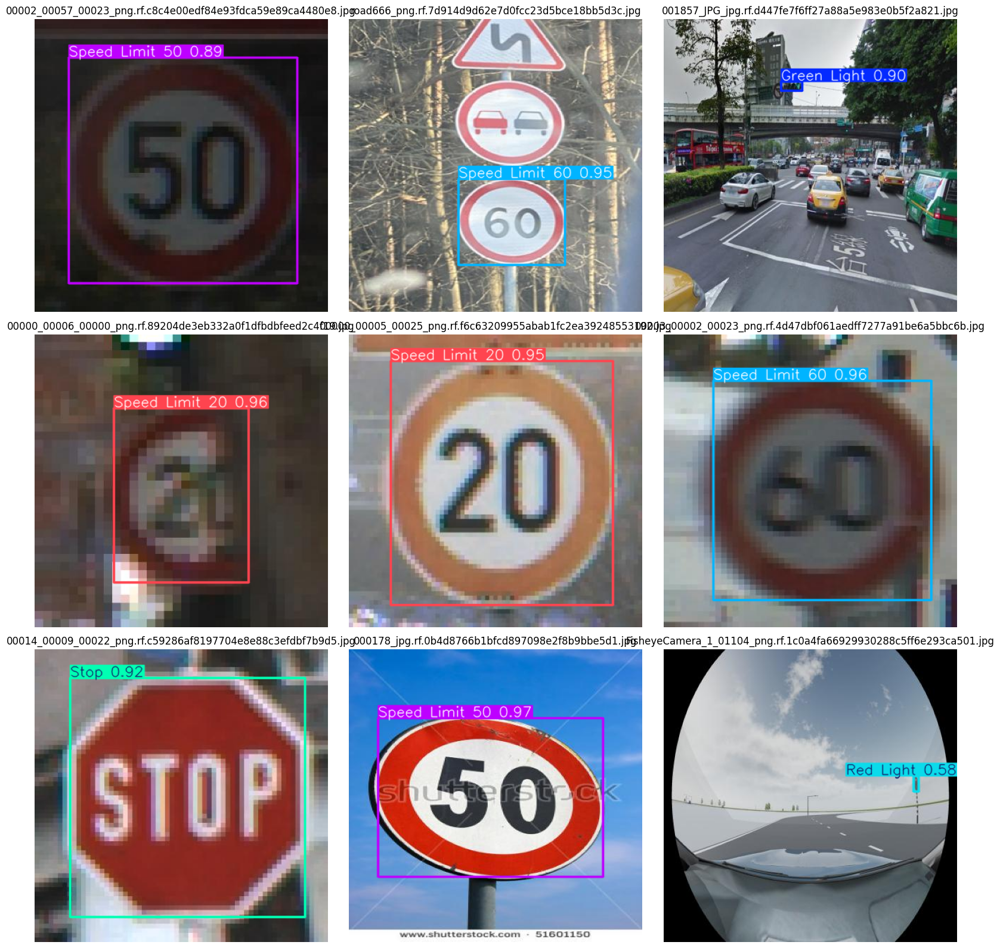

In [37]:
# ============================================================
# STEP 36: TEST IMAGE PREDICTIONS
# ============================================================

import random

NUM_SAMPLES = min(
    9,
    len(test_images)
)

selected_images = random.sample(
    test_images,
    NUM_SAMPLES
)

fig, axes = plt.subplots(
    3,
    3,
    figsize=(16, 16)
)

axes = axes.flatten()

for i, image_path in enumerate(
    selected_images
):

    prediction = best_model.predict(

        source=str(image_path),

        imgsz=640,

        conf=0.25,

        device=0,

        verbose=False
    )

    annotated = prediction[0].plot()

    annotated = cv2.cvtColor(
        annotated,
        cv2.COLOR_BGR2RGB
    )

    axes[i].imshow(
        annotated
    )

    axes[i].set_title(
        image_path.name
    )

    axes[i].axis("off")


for i in range(
    NUM_SAMPLES,
    9
):

    axes[i].axis("off")


plt.tight_layout()
plt.show()

Results saved to /kaggle/working/runs/detect/predict


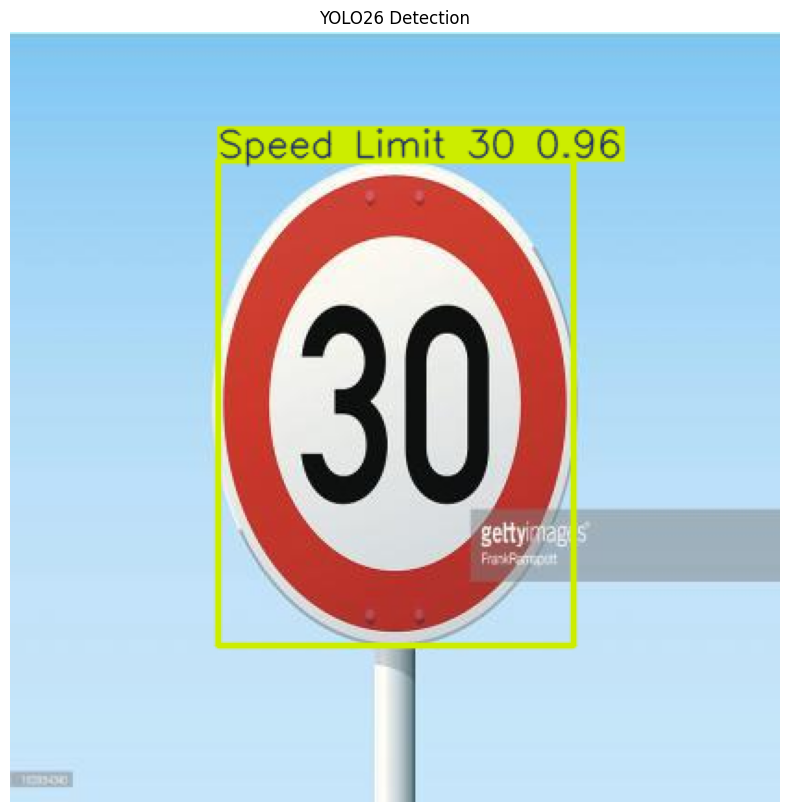

In [38]:
# ============================================================
# STEP 37: SINGLE IMAGE PREDICTION
# ============================================================

IMAGE_PATH = test_images[0]

prediction = best_model.predict(

    source=str(IMAGE_PATH),

    imgsz=640,

    conf=0.30,

    device=0,

    save=True,

    verbose=False
)

annotated = prediction[0].plot()

plt.figure(
    figsize=(12, 10)
)

plt.imshow(
    cv2.cvtColor(
        annotated,
        cv2.COLOR_BGR2RGB
    )
)

plt.title(
    "YOLO26 Detection"
)

plt.axis("off")

plt.show()

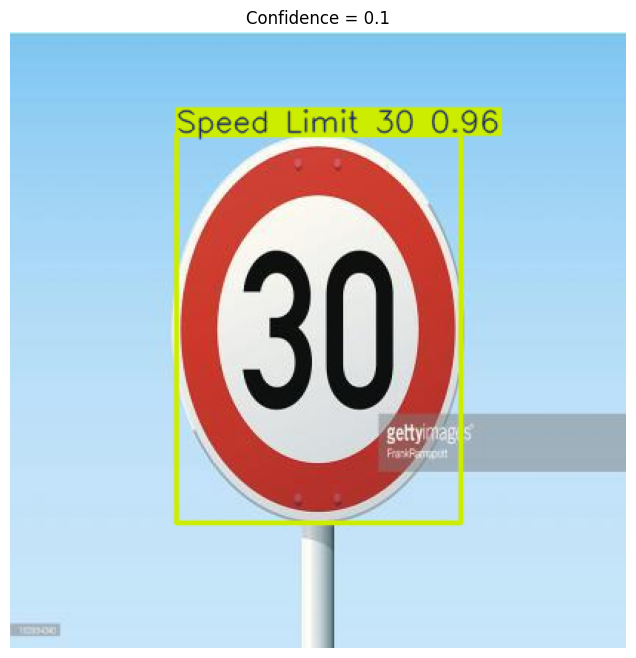

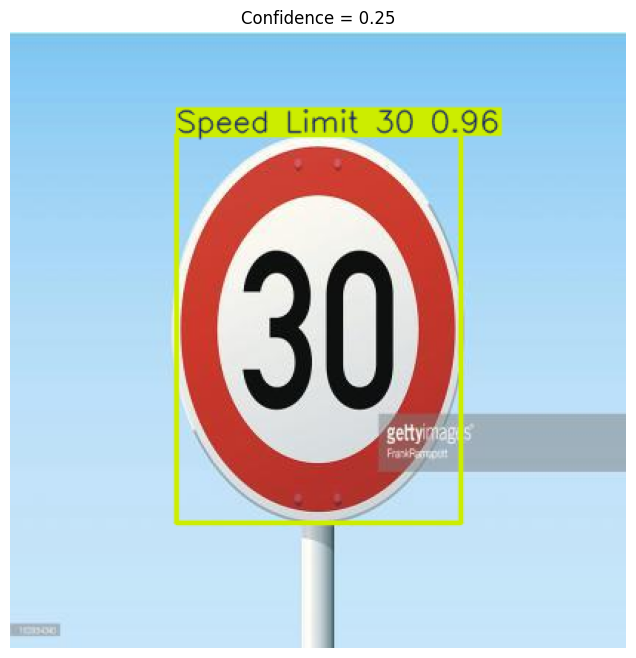

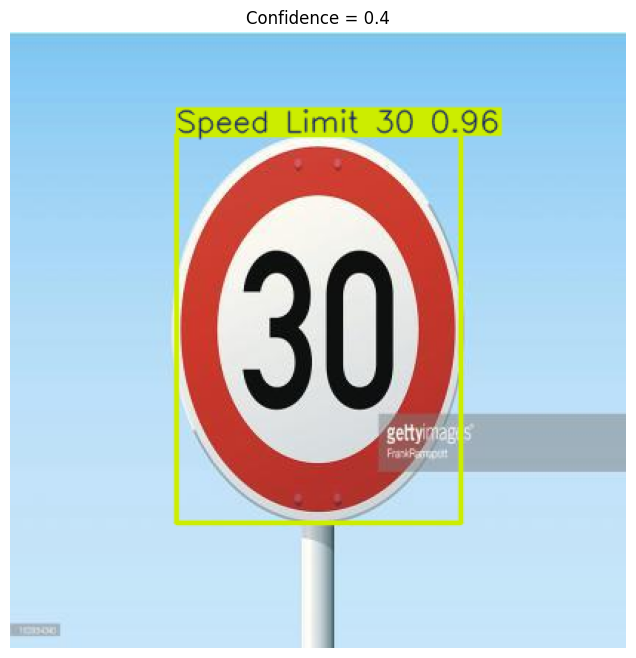

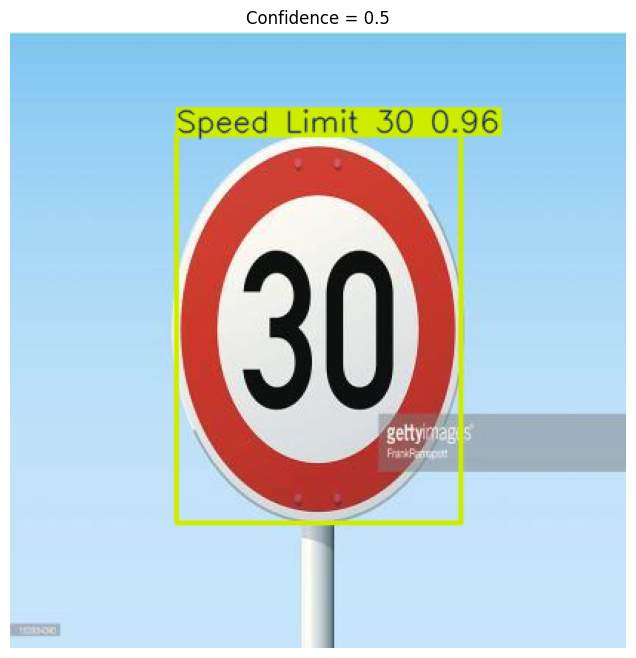

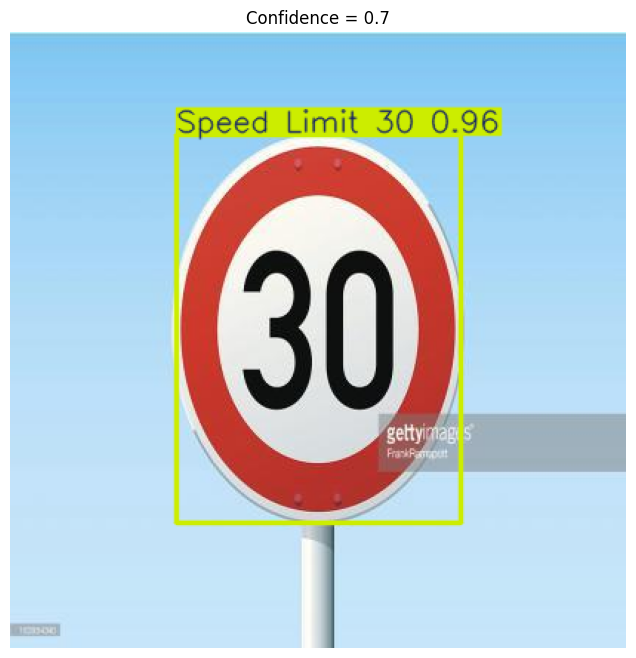

In [39]:
# ============================================================
# STEP 38: CONFIDENCE THRESHOLD TEST
# ============================================================

confidence_values = [
    0.10,
    0.25,
    0.40,
    0.50,
    0.70
]

for confidence in confidence_values:

    prediction = best_model.predict(

        source=str(IMAGE_PATH),

        imgsz=640,

        conf=confidence,

        device=0,

        verbose=False
    )

    annotated = prediction[0].plot()

    plt.figure(
        figsize=(10, 8)
    )

    plt.imshow(
        cv2.cvtColor(
            annotated,
            cv2.COLOR_BGR2RGB
        )
    )

    plt.title(
        f"Confidence = {confidence}"
    )

    plt.axis("off")

    plt.show()

In [40]:
# ============================================================
# STEP 39: EXPORT ONNX
# ============================================================

onnx_path = best_model.export(

    format="onnx",

    imgsz=640,

    simplify=True
)

print(
    "ONNX model exported:"
)

print(
    onnx_path
)

Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.10.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino/

PyTorch: starting from '/kaggle/working/runs/cardetection_yolo26_2gpu/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 300, 6) (5.2 MB)
requirements: Ultralytics requirements ['onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 12 packages in 393ms
 Downloaded onnxruntime
Prepared 2 packages in 338ms
Installed 2 packages in 32ms
 + onnxruntime==1.28.0
 + onnxslim==0.1.96

requirements: AutoUpdate success ✅ 1.3s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.22.0 opset 20...
ONNX: slimming with onnxslim 0.1.96...
ONNX: export success ✅ 3.3s, saved as '/kaggle/working/runs/cardetection_yolo

In [41]:
# ============================================================
# STEP 40: SAVE FINAL BEST.PT
# ============================================================

import shutil

FINAL_MODEL = Path(
    "/kaggle/working/cardetection_yolo26_best.pt"
)

shutil.copy(
    BEST_MODEL,
    FINAL_MODEL
)

print(
    "Final model:"
)

print(
    FINAL_MODEL
)

print(
    f"\nModel size: "
    f"{FINAL_MODEL.stat().st_size / (1024**2):.2f} MB"
)

Final model:
/kaggle/working/cardetection_yolo26_best.pt

Model size: 5.15 MB


In [42]:
# ============================================================
# STEP 41: LOAD FINAL MODEL
# ============================================================

deployment_model = YOLO(
    str(FINAL_MODEL)
)

print(
    "✓ Final YOLO26 model loaded."
)

✓ Final YOLO26 model loaded.


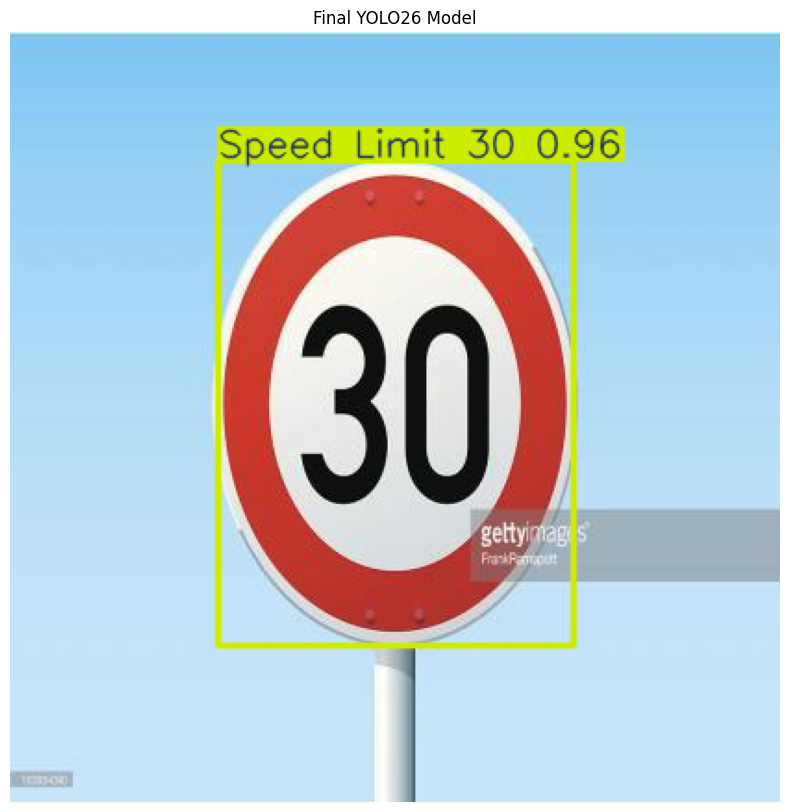

In [43]:
# ============================================================
# STEP 42: FINAL INFERENCE TEST
# ============================================================

final_result = deployment_model.predict(

    source=str(IMAGE_PATH),

    imgsz=640,

    conf=0.30,

    device=0,

    verbose=False
)

annotated = final_result[0].plot()

plt.figure(
    figsize=(12, 10)
)

plt.imshow(
    cv2.cvtColor(
        annotated,
        cv2.COLOR_BGR2RGB
    )
)

plt.title(
    "Final YOLO26 Model"
)

plt.axis("off")

plt.show()

In [44]:
# ============================================================
# STEP 43: FINAL SUMMARY
# ============================================================

print("=" * 70)
print("YOLO26 TRAINING COMPLETE")
print("=" * 70)

print("\nDataset:")
print(DATASET_DIR)

print("\nData YAML:")
print(DATA_YAML)

print("\nModel:")
print("YOLO26n")

print("\nGPUs:")
print("GPU 0: Tesla T4")
print("GPU 1: Tesla T4")

print("\nBatch:")
print("16")

print("\nImage size:")
print("640")

print("\nEpochs:")
print("100")

print("\nBest model:")
print(BEST_MODEL)

print("\nFinal model:")
print(FINAL_MODEL)

print("\nONNX:")
print(onnx_path)

print("\nTraining directory:")
print(RUN_DIR)

print("\n" + "=" * 70)
print("DONE")
print("=" * 70)

YOLO26 TRAINING COMPLETE

Dataset:
/kaggle/input/datasets/pkdarabi/cardetection/car

Data YAML:
/kaggle/input/datasets/pkdarabi/cardetection/car/data.yaml

Model:
YOLO26n

GPUs:
GPU 0: Tesla T4
GPU 1: Tesla T4

Batch:
16

Image size:
640

Epochs:
100

Best model:
/kaggle/working/runs/cardetection_yolo26_2gpu/weights/best.pt

Final model:
/kaggle/working/cardetection_yolo26_best.pt

ONNX:
/kaggle/working/runs/cardetection_yolo26_2gpu/weights/best.onnx

Training directory:
/kaggle/working/runs/cardetection_yolo26_2gpu

DONE
